# H6 — Guarded hybrid recovery

A reproducible, **synthetic offline** example joining H5 landing recovery to a two-mission schedule. The quantum calculation uses the existing local noiseless QAOA simulator; **hardware jobs and provider charges: zero**.

The classical answer is prepared first. QAOA runs in one bounded background worker. A result is used only if its input is current, it meets its acceptance deadline, its measured plan passes the original constraints, and its score is at least the classical incumbent's score. This small example demonstrates integration, not quantum advantage or flight qualification.

Run all cells using **Lunar H0 (Python 3.12)**. The notebook imports production modules and reads the versioned example; it does not import tests.

In [1]:
from pathlib import Path
from copy import deepcopy
from html import escape
import json
import os
import sys
from IPython.display import HTML, SVG, display
start = Path(os.environ.get("LUNAR_REPO_ROOT", Path.cwd())).resolve()
roots = [start, *start.parents, start / "quantum-hybrid-workspace"]
ROOT = next((p for p in roots if (p / "backend/app/hybrid_recovery.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open inside the repository or set LUNAR_REPO_ROOT.")
sys.path.insert(0, str(ROOT))
from backend.app.self_healing import RecoveryScenario, replay_recovery
from backend.app.hybrid_recovery import (
    HybridRecoveryRequest, QuantumBudget, RecoveryCoordinator,
    checkpoint_from_decision, prepare_problem, replay_hybrid,
)
from backend.app.hybrid_planning import solve_exact, validate_plan
from shared.hybrid import Plan, Scenario

def table(headers, rows):
    def row(values, tag):
        return "<tr>" + "".join(f"<{tag}>{escape(str(v))}</{tag}>" for v in values) + "</tr>"
    display(HTML("<table>" + row(headers, "th") + "".join(row(r, "td") for r in rows) + "</table>"))

raw = json.loads((ROOT / "shared/examples/recovery/hybrid_campaign.json").read_text())
budget = QuantumBudget.model_validate(raw.pop("quantum_budget"))
recovery = RecoveryScenario.model_validate(raw["recovery"])
baseline = replay_recovery(recovery)
request = HybridRecoveryRequest.model_validate(dict(
    **raw, checkpoint=checkpoint_from_decision(baseline["decisions"][-1]).model_dump()
))
initial = HybridRecoveryRequest.model_validate(dict(
    **raw, checkpoint=checkpoint_from_decision(baseline["decisions"][0]).model_dump()
))
assert initial.checkpoint.landing_hazards == ()  # Historical snapshot stays unchanged.
print("Synthetic events:", [e.payload.kind for e in recovery.events])
print("Uncertainty draws per target:", recovery.uncertainty.samples)
print("Quantum budget:", budget.model_dump())
print("Planar frame:", request.checkpoint.estimated_state.reference_frame)


Synthetic events: ['propellant_loss', 'thrust_loss', 'landing_hazard']
Uncertainty draws per target: 8
Quantum budget: {'deadline_s': 10.0, 'depth': 1, 'evaluations': 64, 'shots': 256, 'seed': 17, 'max_qubits': 4}
Planar frame: PLANAR_MOON_CENTERED_NONROTATING


## 1. Recheck physical candidates

At 5 seconds, the vehicle loses 3 kg of fuel, its thrust ceiling drops to 3000 N, and the original landing interval closes. H5 alone keeps a feasible nearby backup. H6 re-screens every target from the current **estimated** state, including coarse/fine integration and eight seeded uncertainty draws. Those draws are not a certified safety probability.

In [2]:
prepared = prepare_problem(request)
problem = prepared["scenario"]
assert problem is not None
assert baseline["status"] == "landed" and baseline["selected_target_id"] == "backup"
table(["Target", "Accepted", "Remaining burn (kg)", "Sample passes", "Reasons"], [
    [c["target_id"], c["accepted"], round(c["fine"]["propellant_used_kg"], 6) if "fine" in c else "not simulated",
     f'{c["uncertainty"]["pass_count"]}/{c["uncertainty"]["sample_count"]}', c["reasons"]]
    for c in prepared["physical_candidates"]
])
print("H5 local policy target:", baseline["selected_target_id"])
print("H6 input identity:", prepared["request_sha256"])


Target,Accepted,Remaining burn (kg),Sample passes,Reasons
backup,True,14.883839,8/8,[]
primary,False,not simulated,0/0,['landing_hazard']
remote,True,17.736404,8/8,[]


H5 local policy target: backup
H6 input identity: 2f66df6f719a9f365e23b76192501db661cd6cd9995f6a81539a3641a3b7ce12


## 2. Build the joint campaign

Declared site identifiers link the planar targets to campaign options; no coordinate transformation is inferred. Landing service windows follow predicted touchdown. Downstream slots stay at their declared times. The 80 m target arrives at 35 s, so it cannot precede the 33 s follow-up; the 40 s follow-up remains available. Shared antenna capacity and all other original rules are retained.

A transparent additional objective minimizes remaining propellant use (weight 1, scale 1000 kg by default). The supplied synthetic utility scores favor the remote site's campaign value. They are illustrative, not science measurements.

In [3]:
table(["Option", "Mission", "Start UTC", "End UTC", "Utility", "Remaining burn kg"], [
    [c.option_id, c.mission_id, c.window.start_utc.isoformat(), c.window.end_utc.isoformat(),
     c.metrics["utility"], round(c.metrics["recovery_propellant_kg"], 6)]
    for c in problem.candidates
])
table(["Constraint", "Incompatible options"], [[r.kind, r.option_ids] for r in problem.incompatibilities])
classical = solve_exact(problem)
assert classical.status == "optimal"
classical_check = validate_plan(classical.plan, problem)
assert classical_check.status == "feasible"
assert set(classical.plan.selected_option_ids) == {"land-remote", "follow-late"}
print("Exact classical optimum:", classical.plan.selected_option_ids)
print("Exact score:", classical_check.exact_score)


Option,Mission,Start UTC,End UTC,Utility,Remaining burn kg
follow-early,follow,2030-01-01T00:00:33+00:00,2030-01-01T00:00:34+00:00,40.0,0.0
follow-late,follow,2030-01-01T00:00:40+00:00,2030-01-01T00:00:41+00:00,10.0,0.0
land-backup,landing,2030-01-01T00:00:29.999945+00:00,2030-01-01T00:00:31.999945+00:00,10.0,14.883839
land-remote,landing,2030-01-01T00:00:34.999980+00:00,2030-01-01T00:00:36.999980+00:00,100.0,17.736404


Constraint,Incompatible options
at_most_one,"('follow-early', 'land-remote')"


Exact classical optimum: ('follow-late', 'land-remote')
Exact score: 109982263595723410617/1000000000000000000


## 3. Run the two-qubit worker

Two surviving landing choices × two downstream choices = four basis states, encoded with two logical qubits. Four one-hot QUBO variables are used for the mapping audit. Compilation, tuning and checking still perform classical work; lower qubit count does not imply lower total cost.

The acceptance clock starts after classical preparation. Validation also consumes this deadline. The offline replay pauses simulated flight time during planning, so it does not demonstrate live latency compensation.

In [4]:
coordinator = RecoveryCoordinator()
try:
    ticket = coordinator.submit(request, budget)
    assert ticket.fallback.plan is not None
    print("Classical incumbent ready before quantum acceptance:", ticket.fallback.plan.selected_option_ids)
    result = coordinator.wait(ticket, request)
finally:
    coordinator.close()
assert result["status"] == "selected"
assert result["validation"]["status"] == "feasible"
assert result["validation"]["exact_score"] == classical_check.exact_score
quantum = result["quantum"]
assert quantum is not None and quantum["logical_qubits"] == 2
assert quantum["hardware_jobs"] == 0
assert result["source"] == "quantum", result["reason"]
table(["Source", "Reason", "Target", "Qubits", "Shots", "Classical preparation s", "Elapsed since launch s"], [[
    result["source"], result["reason"], result["selected_target_id"], quantum["logical_qubits"],
    quantum["shots"], round(result["preparation_s"], 4), round(result["elapsed_since_submission_s"], 4)
]])
table(["Basis", "Options", "Probability", "Observed count", "Feasible", "Optimal"], [
    [s["basis_index"], s["selected_option_ids"], round(s["probability"], 6), s["count"], s["feasible"], s["optimal"]]
    for s in quantum["samples"]
])
print("Logical gate estimates (not transpiled hardware):", {k: quantum[k] for k in ("cx_gate_estimate", "rz_gate_estimate", "rx_gate_count", "max_z_locality")})


Classical incumbent ready before quantum acceptance: ('follow-late', 'land-remote')


Source,Reason,Target,Qubits,Shots,Classical preparation s,Elapsed since launch s
quantum,quantum_accepted,remote,2,256,0.4153,0.4041


Basis,Options,Probability,Observed count,Feasible,Optimal
0,"['follow-early', 'land-backup']",0.175544,48,True,False
1,"['follow-late', 'land-backup']",0.235918,52,True,False
2,"['follow-early', 'land-remote']",0.007664,2,False,False
3,"['follow-late', 'land-remote']",0.580875,154,True,True


Logical gate estimates (not transpiled hardware): {'cx_gate_estimate': 2, 'rz_gate_estimate': 3, 'rx_gate_count': 2, 'max_z_locality': 2}


## 4. Three seeds, the same problem and budget

Report raw simulator probabilities and sampled rates, including any inferior run. A valid QAOA proposal that scores below the exact classical incumbent is rejected. The classical reference already solves this four-state problem; matching it is an integration success, not speedup.

In [5]:
benchmarks = []
for seed in (17, 23, 42):
    seeded = QuantumBudget.model_validate(dict(budget.model_dump(), seed=seed))
    coordinator = RecoveryCoordinator()
    try:
        outcome = coordinator.wait(coordinator.submit(request, seeded), request)
    finally:
        coordinator.close()
    q = outcome["quantum"]
    assert outcome["validation"]["status"] == "feasible"
    assert outcome["validation"]["exact_score"] == classical_check.exact_score
    benchmarks.append(dict(seed=seed, source=outcome["source"], reason=outcome["reason"],
        optimal_probability=q["optimal_probability"], uniform=q["uniform_optimal_probability"],
        sampled_optimal_rate=q["sampled_optimal_rate"], quantum_elapsed_s=q["elapsed_s"]))
table(["Seed", "Accepted source", "P(optimum)", "Uniform P(optimum)", "Sampled optimum rate", "Worker s"], [
    [b["seed"], b["source"], round(b["optimal_probability"],6), b["uniform"],
     round(b["sampled_optimal_rate"],6), round(b["quantum_elapsed_s"],4)] for b in benchmarks
])


Seed,Accepted source,P(optimum),Uniform P(optimum),Sampled optimum rate,Worker s
17,quantum,0.580875,0.25,0.601562,0.0323
23,quantum,0.652961,0.25,0.652344,0.0322
42,quantum,0.577499,0.25,0.605469,0.0327


## 5. Deadline and stale-input guards

Use a controlled monotonic clock to demonstrate the exact acceptance boundary without timing-dependent sleeps. A completed result is still discarded at its deadline. Then remove current antenna availability without incrementing the campaign revision: the complete input hash catches the change, and fresh classical validation finds no feasible schedule. An old fallback is never reused blindly.

In [6]:
clock = [0.0]
coordinator = RecoveryCoordinator(clock=lambda: clock[0])
try:
    ticket = coordinator.submit(request, budget)
    ticket.future.result(timeout=30)
    clock[0] = ticket.deadline
    expired = coordinator.resolve(ticket, request)
    assert expired["reason"] == "deadline" and expired["source"] == "classical_fallback"
    assert expired["validation"]["status"] == "feasible"
    changed = request.model_dump(mode="json")
    changed["campaign"]["resources"][0]["availability"] = []
    current = HybridRecoveryRequest.model_validate(changed)
    stale = coordinator.resolve(ticket, current)
    assert stale["reason"] == "stale_snapshot"
    assert stale["status"] == "infeasible" and stale["plan"] is None
finally:
    coordinator.close()
table(["Case", "Reason", "Source", "Status"], [
    [name, r["reason"], r["source"], r["status"]]
    for name, r in (("Acceptance deadline reached", expired), ("Current antenna unavailable", stale))
])


Case,Reason,Source,Status
Acceptance deadline reached,deadline,classical_fallback,selected
Current antenna unavailable,stale_snapshot,classical_fallback,infeasible


## 6. Unsupported encoding and no physical continuation

Before the fault, three landing options do not fit H2's current power-of-two compact encoding. The system preserves the options and uses the validated classical result. If current thrust becomes zero, no screened landing remains and no quantum job is started. Infeasible means no validated continuation among the supplied choices; it is not a safe-abort maneuver.

In [7]:
coordinator = RecoveryCoordinator()
try:
    unsupported = coordinator.wait(coordinator.submit(initial, budget), initial)
    assert unsupported["reason"] == "unsupported"
    assert unsupported["source"] == "classical_fallback"
    assert unsupported["selected_target_id"] == "primary"
    dead = request.model_dump(mode="json")
    dead["checkpoint"]["available_thrust_n"] = 0.0
    dead = HybridRecoveryRequest.model_validate(dead)
    dead_ticket = coordinator.submit(dead, budget)
    assert dead_ticket.future is None
    infeasible = coordinator.resolve(dead_ticket, dead)
    assert infeasible["status"] == "infeasible" and infeasible["selected_target_id"] is None
finally:
    coordinator.close()
table(["Case", "Status", "Reason", "Target"], [
    [name, r["status"], r["reason"], r["selected_target_id"]]
    for name, r in (("Three initial landing options", unsupported), ("Engine unavailable", infeasible))
])
print("Unsupported reason:", unsupported["error"])


Case,Status,Reason,Target
Three initial landing options,selected,unsupported,primary
Engine unavailable,infeasible,infeasible,None


Unsupported reason: Compact encoding requires power-of-two options per mission


## 7. End-to-end offline replay

H5 retains control of physical screening and propagation. H6 can select only a currently accepted target. The initial classical schedule uses the primary target and early follow-up. After the fault, guarded QAOA selects the remote target and late follow-up. The campaign plan records the downstream selection; this notebook does not physically simulate a second vehicle.

In [8]:
hybrid = replay_hybrid(
    recovery, request.campaign, request.landing_mission_id,
    request.bindings, request.dependencies, budget,
)
flight = hybrid["replay"]
assert hybrid["hardware_jobs"] == 0 and hybrid["simulated_clock_paused_during_planning"]
assert flight["status"] == "landed" and flight["selected_target_id"] == "remote"
assert hybrid["decisions"][-1]["source"] == "quantum"
assert set(hybrid["decisions"][-1]["plan"]["selected_option_ids"]) == {"land-remote", "follow-late"}
assert abs(flight["propellant_burned_kg"] + flight["propellant_lost_kg"] + flight["final_state"]["propellant_kg"] - 100) < 1e-8
table(["Decision", "Source", "Target", "Joint plan", "Reason"], [
    [i, r["source"], r["selected_target_id"], r["plan"]["selected_option_ids"], r["reason"]]
    for i, r in enumerate(hybrid["decisions"])
])
table(["Flight policy", "Target", "Touchdown UTC", "Burned kg", "Lost kg", "Remaining kg"], [
    [name, r["selected_target_id"], r["final_state"]["epoch_utc"], round(r["propellant_burned_kg"],6),
     r["propellant_lost_kg"], round(r["final_state"]["propellant_kg"],6)]
    for name, r in (("H5 local target", baseline), ("H6 joint schedule", flight))
])


Decision,Source,Target,Joint plan,Reason
0,classical_fallback,primary,"['follow-early', 'land-primary']",unsupported
1,quantum,remote,"['follow-late', 'land-remote']",quantum_accepted


Flight policy,Target,Touchdown UTC,Burned kg,Lost kg,Remaining kg
H5 local target,backup,2030-01-01T00:00:29.999953Z,17.333022,3.0,79.666978
H6 joint schedule,remote,2030-01-01T00:00:34.999982Z,20.185561,3.0,76.814439


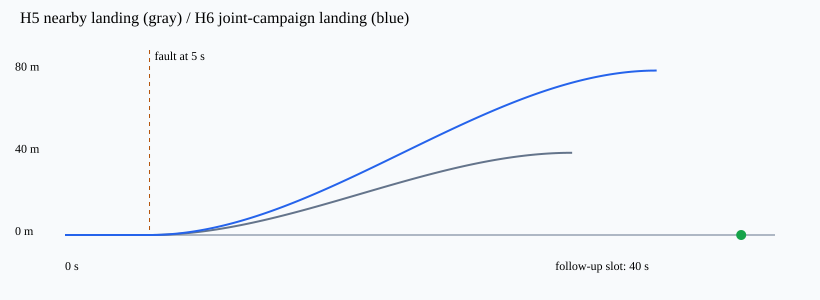

In [9]:
left, right, top, bottom = 65, 775, 50, 235
x = lambda t: left + t / 42 * (right-left)
y = lambda d: bottom - d / 90 * (bottom-top)
paths = []
for run, color in ((baseline,"#64748b"),(flight,"#2563eb")):
    points = " ".join(f'{x(r["elapsed_s"]):.3f},{y(r["downrange_m"]):.3f}' for r in run["trace"])
    paths.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="820" height="300"><rect width="100%" height="100%" fill="#f8fafc"/><text x="20" y="23" font-size="16">H5 nearby landing (gray) / H6 joint-campaign landing (blue)</text><line x1="{left}" y1="{bottom}" x2="{right}" y2="{bottom}" stroke="#64748b"/><line x1="{x(5)}" y1="{top}" x2="{x(5)}" y2="{bottom}" stroke="#b45309" stroke-dasharray="4 4"/><text x="{x(5)+5}" y="60" font-size="12">fault at 5 s</text><text x="15" y="{y(80)}" font-size="12">80 m</text><text x="15" y="{y(40)}" font-size="12">40 m</text><text x="15" y="{bottom}" font-size="12">0 m</text><circle cx="{x(40)}" cy="{bottom}" r="5" fill="#16a34a"/><text x="{x(29)}" y="270" font-size="12">follow-up slot: 40 s</text><text x="{left}" y="270" font-size="12">0 s</text>{"".join(paths)}</svg>'))


## 8. What this proves, and what remains

- The current physical estimate and campaign constraints determine the accepted plan, including after a deadline or stale-result rejection.
- Two-qubit local QAOA can produce the same optimal joint plan as exhaustive enumeration on this small example. All seeds and raw outcomes are reported; no hardware or end-to-end quantum advantage is established.
- Eight finite uncertainty draws, a planar descent model and a sampled terrain corridor do not establish real-flight safety.
- The worker has one slot and bounded QAOA settings. Running Python work is not forcibly killed; `close()` waits for it. The API is an offline coordination layer, not a hard real-time actuator controller.
- H7 remains responsible for separately authorized hardware experiments, calibrated noise/cost measurements and broader reproducible benchmarks.

See `docs/hybrid-recovery.md` for contracts, timing semantics and frozen acceptance tests.

In [10]:
summary = dict(
    local_quantum_qubits=quantum["logical_qubits"], hardware_jobs=0,
    final_target=flight["selected_target_id"],
    final_schedule=hybrid["decisions"][-1]["plan"]["selected_option_ids"],
    final_fuel_kg=flight["final_state"]["propellant_kg"],
    quantum_matches_classical=result["validation"]["exact_score"] == classical_check.exact_score,
    seed_results=benchmarks,
    timing_scope="quantum acceptance after classical preparation; offline simulated clock paused",
)
print(json.dumps(summary, indent=2))
print("H6 notebook assertions passed. No provider jobs were submitted.")


{
  "local_quantum_qubits": 2,
  "hardware_jobs": 0,
  "final_target": "remote",
  "final_schedule": [
    "follow-late",
    "land-remote"
  ],
  "final_fuel_kg": 76.81443885247847,
  "quantum_matches_classical": true,
  "seed_results": [
    {
      "seed": 17,
      "source": "quantum",
      "reason": "quantum_accepted",
      "optimal_probability": 0.580874940453549,
      "uniform": 0.25,
      "sampled_optimal_rate": 0.6015625,
      "quantum_elapsed_s": 0.03228187499917112
    },
    {
      "seed": 23,
      "source": "quantum",
      "reason": "quantum_accepted",
      "optimal_probability": 0.6529605733431386,
      "uniform": 0.25,
      "sampled_optimal_rate": 0.65234375,
      "quantum_elapsed_s": 0.03223633299785433
    },
    {
      "seed": 42,
      "source": "quantum",
      "reason": "quantum_accepted",
      "optimal_probability": 0.577498541549992,
      "uniform": 0.25,
      "sampled_optimal_rate": 0.60546875,
      "quantum_elapsed_s": 0.0326668330017128
    }
